##  1.. Data Collection !

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import glob

In [5]:
### since we have used 'os' package already in youtube case-study to access data, lets use glob module this time ..

In [6]:
glob.glob(r"D:\Data_Aanalytic_Projects_DA\Project - 2 Stock_price_analysis\individual_stocks_5yr\*.csv")

['D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\AAL_data.csv',
 'D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\AAPL_data.csv',
 'D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\AAP_data.csv',
 'D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\ABBV_data.csv',
 'D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\ABC_data.csv',
 'D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\ABT_data.csv',
 'D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\ACN_data.csv',
 'D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\ADBE_data.csv',
 'D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\ADI_data.csv',
 'D:\\Data_Aanalytic_Projects_DA\\Project -

In [7]:
len(glob.glob(r"D:\Data_Aanalytic_Projects_DA\Project - 2 Stock_price_analysis\individual_stocks_5yr\*.csv")) ## total files we have 

505

In [8]:
# lets store files of those stock that we have to consider for analysis ..

In [9]:
company_list = [
    r'D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\AAPL_data.csv' , 
    r'D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\AMZN_data.csv' , 
    r'D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\GOOG_data.csv' , 
    r'D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\MSFT_data.csv'
    
]

In [10]:
## use Warnings package to get rid of any future warning ..

import warnings
from warnings import filterwarnings
filterwarnings('ignore')

In [11]:
### in the utube case-study , we have used pandas concat() to collect data from various files ..
## so this time , lets use pandas append() to do same task..

In [12]:
all_data = pd.DataFrame()

for file in company_list:

    current_df = pd.read_csv(file)

    all_data = pd.concat([all_data, current_df], ignore_index=True)

In [13]:
all_data.shape ## dimensions of all_data dataframe ..

(4752, 7)

In [14]:
all_data.head(6)

,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL
5,2013-02-15,66.9785,67.1656,65.7028,65.7371,97924631,AAPL


In [15]:
all_data['Name'].unique()

array(['AAPL', 'AMZN', 'GOOG', 'MSFT'], dtype=object)

## 2.. Data Cleaning 


In [16]:
all_data.dtypes

date       object
open      float64
high      float64
low       float64
close     float64
volume      int64
Name       object
dtype: object

In [17]:
all_data["date"] = pd.to_datetime(all_data["date"])

In [18]:
all_data.dtypes

date      datetime64[ns]
open             float64
high             float64
low              float64
close            float64
volume             int64
Name              object
dtype: object

In [19]:
all_data.isnull().sum() ## checking missing values 

date      0
open      0
high      0
low       0
close     0
volume    0
Name      0
dtype: int64

In [20]:
all_data.duplicated().sum()

np.int64(0)

In [21]:
all_data[all_data["volume"]<=0]# checking for any negative or zero volume values in the  data set...

,date,open,high,low,close,volume,Name


In [22]:
all_data["Name"].unique()

array(['AAPL', 'AMZN', 'GOOG', 'MSFT'], dtype=object)

In [23]:
all_data.head(6)

,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL
5,2013-02-15,66.9785,67.1656,65.7028,65.7371,97924631,AAPL


In [24]:
all_data.sort_values(["Name", "date"])

,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL
...,...,...,...,...,...,...,...
4747,2018-02-01,94.7900,96.0700,93.5813,94.2600,47227882,MSFT
4748,2018-02-02,93.6400,93.9700,91.5000,91.7800,47867753,MSFT
4749,2018-02-05,90.5600,93.2400,88.0000,88.0000,51031465,MSFT
4750,2018-02-06,86.8900,91.4750,85.2500,91.3300,67998564,MSFT


In [25]:
all_data = all_data.sort_values(["Name", "date"]) # data have been sorted based on stock name and date for better analysis and visualisation..

# 3 which is the safest stcok to invest


In [26]:
all_data["daily_return"] = all_data.groupby("Name")["close"].pct_change()

In [27]:
risk = all_data.groupby("Name")["daily_return"].std()

In [28]:
risk

Name
AAPL    0.014593
AMZN    0.018235
GOOG    0.014069
MSFT    0.014210
Name: daily_return, dtype: float64

In [29]:
safest_stock = risk.idxmin()

In [30]:
safest_stock

'GOOG'

# 4 which stock made the highest money 

In [31]:
all_data["daily_return"]

0            NaN
1       0.010422
2      -0.025067
3      -0.001903
4      -0.000899
          ...   
4747   -0.007894
4748   -0.026310
4749   -0.041185
4750    0.037841
4751   -0.018833
Name: daily_return, Length: 4752, dtype: float64

In [32]:
( 1+all_data["daily_return"]).groupby(all_data["Name"]).cumprod()

0            NaN
1       1.010422
2       0.985095
3       0.983220
4       0.982336
          ...   
4747    3.421416
4748    3.331397
4749    3.194192
4750    3.315064
4751    3.252632
Name: daily_return, Length: 4752, dtype: float64

In [33]:
all_data["cumulative_return"] = ( 1+all_data["daily_return"]).groupby(all_data["Name"]).cumprod()

In [34]:
final_returns = all_data.groupby("Name")["cumulative_return"].last()
final_returns

Name
AAPL    2.351218
AMZN    5.408589
GOOG    1.877628
MSFT    3.252632
Name: cumulative_return, dtype: float64

In [35]:
best_stock = final_returns.idxmax() 
best_stock

'AMZN'

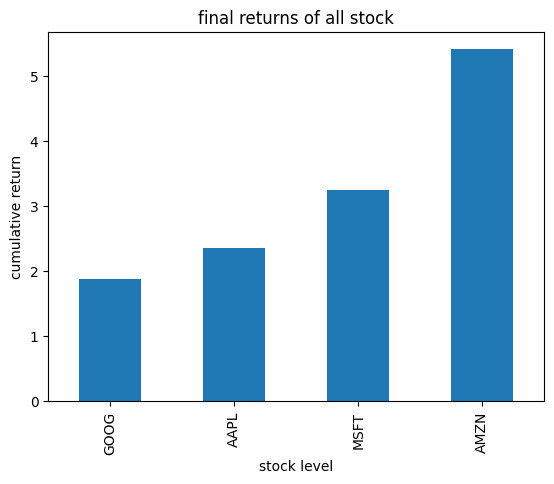

In [36]:
final_returns.sort_values().plot(kind = "bar")
plt.title("final returns of all stock")
plt.ylabel("cumulative return")
plt.xlabel("stock level")
plt.show()



# 5.  1 lakh/Million SAFE Investmenet Simulation

In [37]:
best_stock = final_returns.idxmax() 

In [38]:
best_stock

'AMZN'

In [39]:
investment = 1000000

In [40]:
all_data[all_data["Name"] == best_stock]

,date,open,high,low,close,volume,Name,daily_return,cumulative_return
1259,2013-02-08,261.40,265.25,260.555,261.95,3879078,AMZN,NaN,NaN
1260,2013-02-11,263.20,263.25,256.600,257.21,3403403,AMZN,-0.018095,0.981905
1261,2013-02-12,259.19,260.16,257.000,258.70,2938660,AMZN,0.005793,0.987593
1262,2013-02-13,261.53,269.96,260.300,269.47,5292996,AMZN,0.041631,1.028708
1263,2013-02-14,267.37,270.65,265.400,269.24,3462780,AMZN,-0.000854,1.027830
...,...,...,...,...,...,...,...,...,...
2513,2018-02-01,1445.00,1459.88,1385.140,1390.00,9113808,AMZN,-0.041967,5.306356
2514,2018-02-02,1477.39,1498.00,1414.000,1429.95,11125722,AMZN,0.028741,5.458866
2515,2018-02-05,1402.62,1458.98,1320.720,1390.00,11494985,AMZN,-0.027938,5.306356
2516,2018-02-06,1361.46,1443.99,1351.790,1442.84,11066819,AMZN,0.038014,5.508074


In [41]:
df_best = all_data[all_data["Name"] == best_stock]

In [42]:
df_best

,date,open,high,low,close,volume,Name,daily_return,cumulative_return
1259,2013-02-08,261.40,265.25,260.555,261.95,3879078,AMZN,NaN,NaN
1260,2013-02-11,263.20,263.25,256.600,257.21,3403403,AMZN,-0.018095,0.981905
1261,2013-02-12,259.19,260.16,257.000,258.70,2938660,AMZN,0.005793,0.987593
1262,2013-02-13,261.53,269.96,260.300,269.47,5292996,AMZN,0.041631,1.028708
1263,2013-02-14,267.37,270.65,265.400,269.24,3462780,AMZN,-0.000854,1.027830
...,...,...,...,...,...,...,...,...,...
2513,2018-02-01,1445.00,1459.88,1385.140,1390.00,9113808,AMZN,-0.041967,5.306356
2514,2018-02-02,1477.39,1498.00,1414.000,1429.95,11125722,AMZN,0.028741,5.458866
2515,2018-02-05,1402.62,1458.98,1320.720,1390.00,11494985,AMZN,-0.027938,5.306356
2516,2018-02-06,1361.46,1443.99,1351.790,1442.84,11066819,AMZN,0.038014,5.508074


In [43]:
df_best["cumulative_return"]* investment

1259             NaN
1260    9.819049e+05
1261    9.875931e+05
1262    1.028708e+06
1263    1.027830e+06
            ...     
2513    5.306356e+06
2514    5.458866e+06
2515    5.306356e+06
2516    5.508074e+06
2517    5.408589e+06
Name: cumulative_return, Length: 1259, dtype: float64

In [44]:
df_best["investment_value"]=df_best["cumulative_return"]* investment

In [45]:
df_best["investment_value"]

1259             NaN
1260    9.819049e+05
1261    9.875931e+05
1262    1.028708e+06
1263    1.027830e+06
            ...     
2513    5.306356e+06
2514    5.458866e+06
2515    5.306356e+06
2516    5.508074e+06
2517    5.408589e+06
Name: investment_value, Length: 1259, dtype: float64

In [46]:
df_best["investment_value"].tail(1).values[0]

np.float64(5408589.425462884)

In [47]:
df_best.columns

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'Name',
       'daily_return', 'cumulative_return', 'investment_value'],
      dtype='object')

In [48]:
import plotly.express as px

In [49]:
px.line(
    df_best,
    x="date",
    y="investment_value",
    title=f"1 Million Invest for Growth - {best_stock}",
    labels={
        "investment_value": "Portfolio Value",
        "date": "Date"
    }
)

# 6. Analysing change in price of the stock overtime !

In [50]:
all_data.dtypes ## checking data-types 

date                 datetime64[ns]
open                        float64
high                        float64
low                         float64
close                       float64
volume                        int64
Name                         object
daily_return                float64
cumulative_return           float64
dtype: object

In [51]:
all_data['date'] = pd.to_datetime(all_data['date']) ## converting data-type of "date" featuer into date-time ..

In [52]:
all_data['date']

0      2013-02-08
1      2013-02-11
2      2013-02-12
3      2013-02-13
4      2013-02-14
          ...    
4747   2018-02-01
4748   2018-02-02
4749   2018-02-05
4750   2018-02-06
4751   2018-02-07
Name: date, Length: 4752, dtype: datetime64[ns]

In [53]:
tech_list = all_data['Name'].unique()

In [54]:
tech_list

array(['AAPL', 'AMZN', 'GOOG', 'MSFT'], dtype=object)

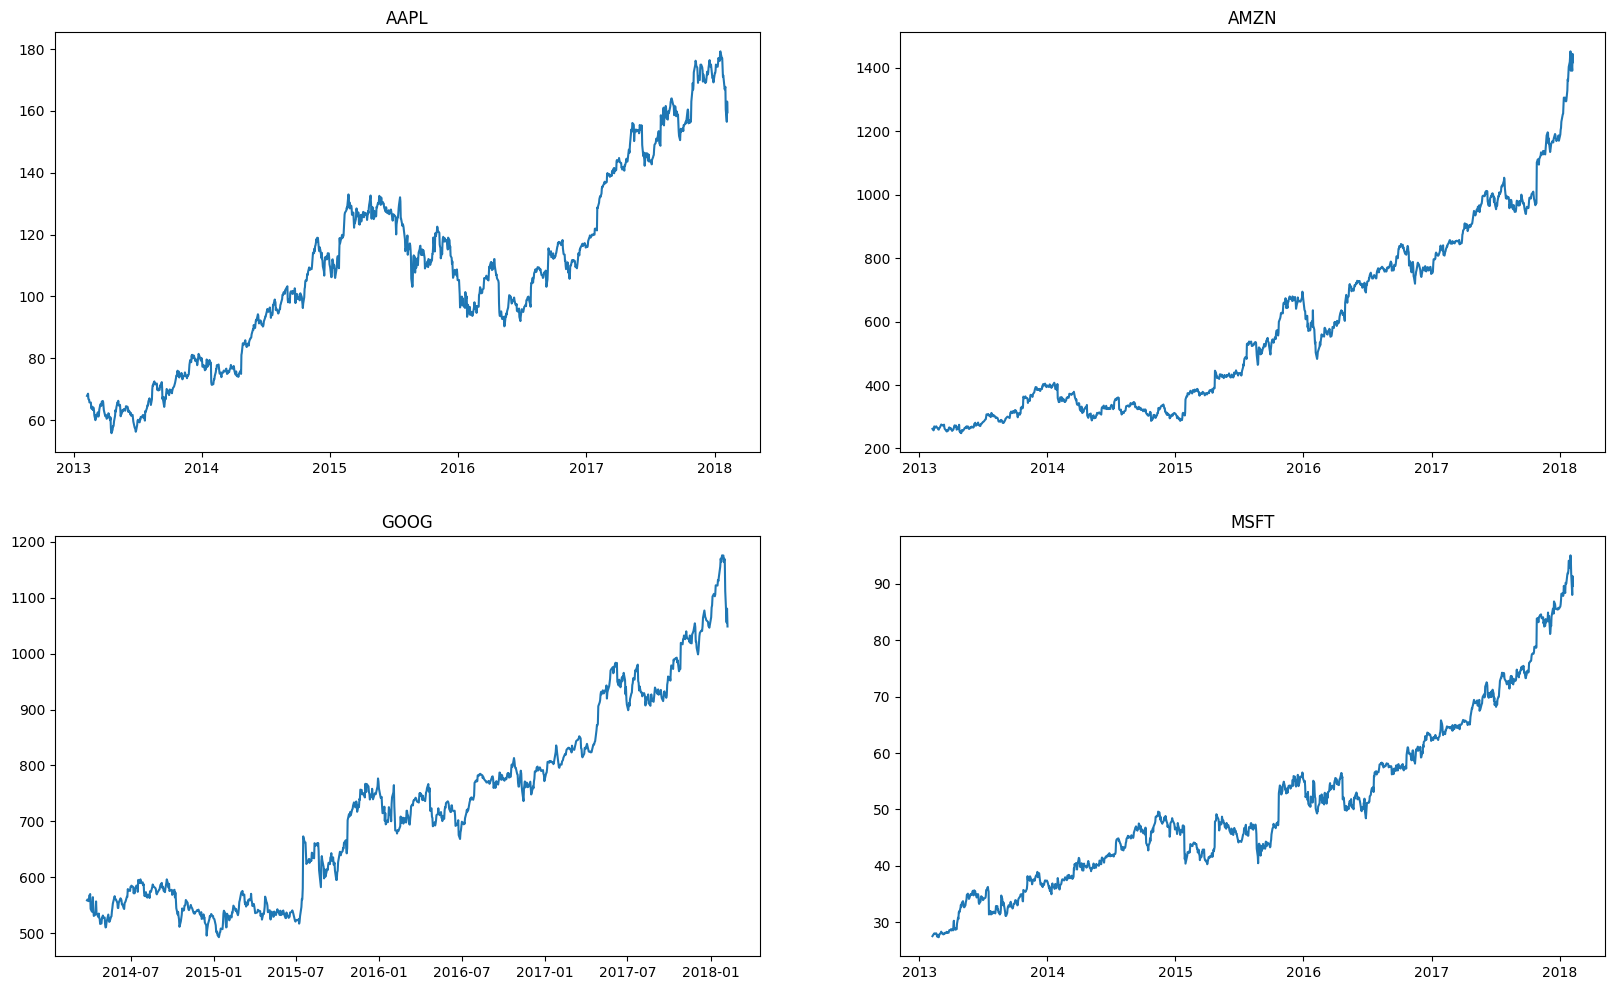

In [55]:
plt.figure(figsize=(20,12))

for index , company in enumerate(tech_list , 1):
    plt.subplot(2 , 2 , index) ## creating subplot for each stock
    filter1 = all_data['Name']==company
    df = all_data[filter1]
    plt.plot(df['date'] , df['close']) ## plotting "date" vs "close"
    plt.title(company)

# 7. Market Crash Days : Worst Losses Analysis


In [56]:
all_data[all_data["Name"] == "AAPL"].nsmallest(5, "daily_return")

,date,open,high,low,close,volume,Name,daily_return,cumulative_return
243,2014-01-28,72.6799,73.5714,71.7242,72.3571,266833581,AAPL,-0.079927,1.066361
746,2016-01-27,96.0400,96.6289,93.3400,93.4200,133369674,AAPL,-0.065707,1.376775
809,2016-04-27,96.0000,98.7100,95.6800,97.8200,114602142,AAPL,-0.062578,1.441620
638,2015-08-21,110.4300,111.9000,105.6450,105.7600,128275471,AAPL,-0.061163,1.558636
46,2013-04-17,60.0385,60.0857,56.8728,57.5428,236138966,AAPL,-0.054993,0.848036


In [57]:
all_data.groupby("Name").apply(lambda x : x.nsmallest(5, "daily_return"))

date       open       high        low      close     volume  \
Name                                                                          
AAPL 243  2014-01-28    72.6799    73.5714    71.7242    72.3571  266833581   
     746  2016-01-27    96.0400    96.6289    93.3400    93.4200  133369674   
     809  2016-04-27    96.0000    98.7100    95.6800    97.8200  114602142   
     638  2015-08-21   110.4300   111.9000   105.6450   105.7600  128275471   
     46   2013-04-17    60.0385    60.0857    56.8728    57.5428  236138966   
AMZN 1505 2014-01-31   371.7600   375.4500   357.7600   358.6900   16181519   
     1563 2014-04-25   316.2500   316.4900   302.7100   303.8300   16186737   
     1626 2014-07-25   317.3000   324.8700   314.7600   324.0100   17855141   
     1690 2014-10-24   284.4000   293.8100   284.0000   287.0600   19805911   
     2007 2016-01-29   571.9800   593.0000   570.0000   587.0000   14677550   
GOOG 3040 2016-04-22   726.3000   736.1200   713.6100   718.7700    5951938   
     2872 2015-08-21   639.7800   640.0500   612.3300   612.4800    4265183   
     3490 2018-02-05  1090.6000  1110.0000  1052.0300  1055.8000    3798301   
     2985 2016-02-03   770.2200   774.5000   720.5000   726.9500    6171019   
     3489 2018-02-02  1122.0000  1123.0700  1107.2800  1111.9000    4857943   
MSFT 3604 2013-07-19    32.4000    32.6700    31.0200    31.4000  248354245   
     3987 2015-01-27    42.9500    43.2000    42.1050    42.6600  169163953   
     4299 2016-04-22    51.9100    52.4297    50.7700    51.7800  126834091   
     4131 2015-08-21    45.3000    45.4800    43.0700    43.0700   70053084   
     3635 2013-09-03    31.7500    32.0700    31.2900    31.8800  154489546   

           Name  daily_return  cumulative_return  
Name                                              
AAPL 243   AAPL     -0.079927           1.066361  
     746   AAPL     -0.065707           1.376775  
     809   AAPL     -0.062578           1.441620  
     638   AAPL     -0.061163           1.558636  
     46    AAPL     -0.054993           0.848036  
AMZN 1505  AMZN     -0.109972           1.369307  
     1563  AMZN     -0.098828           1.159878  
     1626  AMZN     -0.096484           1.236915  
     1690  AMZN     -0.083403           1.095858  
     2007  AMZN     -0.076100           2.240886  
GOOG 3040  GOOG     -0.053179           1.287057  
     2872  GOOG     -0.053105           1.096730  
     3490  GOOG     -0.050454           1.890556  
     2985  GOOG     -0.049304           1.301705  
     3489  GOOG     -0.047786           1.991011  
MSFT 3604  MSFT     -0.113995           1.139746  
     3987  MSFT     -0.092534           1.548457  
     4299  MSFT     -0.071710           1.879492  
     4131  MSFT     -0.056724           1.563339  
     3635  MSFT     -0.045509           1.157169

In [58]:
worst_days = all_data.groupby("Name", group_keys=False).apply(lambda x : x.nsmallest(5, "daily_return"))

In [59]:
worst_days

,date,open,high,low,close,volume,Name,daily_return,cumulative_return
243,2014-01-28,72.6799,73.5714,71.7242,72.3571,266833581,AAPL,-0.079927,1.066361
746,2016-01-27,96.0400,96.6289,93.3400,93.4200,133369674,AAPL,-0.065707,1.376775
809,2016-04-27,96.0000,98.7100,95.6800,97.8200,114602142,AAPL,-0.062578,1.441620
638,2015-08-21,110.4300,111.9000,105.6450,105.7600,128275471,AAPL,-0.061163,1.558636
46,2013-04-17,60.0385,60.0857,56.8728,57.5428,236138966,AAPL,-0.054993,0.848036
1505,2014-01-31,371.7600,375.4500,357.7600,358.6900,16181519,AMZN,-0.109972,1.369307
1563,2014-04-25,316.2500,316.4900,302.7100,303.8300,16186737,AMZN,-0.098828,1.159878
1626,2014-07-25,317.3000,324.8700,314.7600,324.0100,17855141,AMZN,-0.096484,1.236915
1690,2014-10-24,284.4000,293.8100,284.0000,287.0600,19805911,AMZN,-0.083403,1.095858
2007,2016-01-29,571.9800,593.0000,570.0000,587.0000,14677550,AMZN,-0.076100,2.240886


In [60]:
worst_days[["Name", "date", "daily_return"]]

,Name,date,daily_return
243,AAPL,2014-01-28,-0.079927
746,AAPL,2016-01-27,-0.065707
809,AAPL,2016-04-27,-0.062578
638,AAPL,2015-08-21,-0.061163
46,AAPL,2013-04-17,-0.054993
1505,AMZN,2014-01-31,-0.109972
1563,AMZN,2014-04-25,-0.098828
1626,AMZN,2014-07-25,-0.096484
1690,AMZN,2014-10-24,-0.083403
2007,AMZN,2016-01-29,-0.076100


In [61]:
fig = px.bar(
    worst_days,
    x="date",
    y="daily_return",
    color="Name",
    title="Worst Market Crash Days (Top Losses)"
)

fig.show()

In [62]:
worst_days["crash_label"] = worst_days["Name"] + " | " + worst_days["date"].dt.strftime("%Y-%m-%d")



In [63]:
worst_days

,date,open,high,low,close,volume,Name,daily_return,cumulative_return,crash_label
243,2014-01-28,72.6799,73.5714,71.7242,72.3571,266833581,AAPL,-0.079927,1.066361,AAPL | 2014-01-28
746,2016-01-27,96.0400,96.6289,93.3400,93.4200,133369674,AAPL,-0.065707,1.376775,AAPL | 2016-01-27
809,2016-04-27,96.0000,98.7100,95.6800,97.8200,114602142,AAPL,-0.062578,1.441620,AAPL | 2016-04-27
638,2015-08-21,110.4300,111.9000,105.6450,105.7600,128275471,AAPL,-0.061163,1.558636,AAPL | 2015-08-21
46,2013-04-17,60.0385,60.0857,56.8728,57.5428,236138966,AAPL,-0.054993,0.848036,AAPL | 2013-04-17
1505,2014-01-31,371.7600,375.4500,357.7600,358.6900,16181519,AMZN,-0.109972,1.369307,AMZN | 2014-01-31
1563,2014-04-25,316.2500,316.4900,302.7100,303.8300,16186737,AMZN,-0.098828,1.159878,AMZN | 2014-04-25
1626,2014-07-25,317.3000,324.8700,314.7600,324.0100,17855141,AMZN,-0.096484,1.236915,AMZN | 2014-07-25
1690,2014-10-24,284.4000,293.8100,284.0000,287.0600,19805911,AMZN,-0.083403,1.095858,AMZN | 2014-10-24
2007,2016-01-29,571.9800,593.0000,570.0000,587.0000,14677550,AMZN,-0.076100,2.240886,AMZN | 2016-01-29


In [64]:
fig = px.bar(
    worst_days,
    x="crash_label",
    y="daily_return",
    color="Name",
    title="Worst Market Crash Days (Top Losses)"
)

fig.show()

In [65]:
fig = px.bar(
    worst_days,
    x="crash_label",
    y="daily_return",
    color="Name",
    title="Worst Market Crash Days (Top Losses)",
    labels = {
        "daily_return" : "daily return (loss)"
    }
)
fig.add_hline(y=0) # horizontal line at y=0 to indicate the break-even point for daily returns

fig.show()

## 8 moving average of the various stocks !

In [66]:
all_data.head(15)

,date,open,high,low,close,volume,Name,daily_return,cumulative_return
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL,NaN,NaN
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL,0.010422,1.010422
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL,-0.025067,0.985095
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL,-0.001903,0.983220
4,2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL,-0.000899,0.982336
5,2013-02-15,66.9785,67.1656,65.7028,65.7371,97924631,AAPL,-0.013780,0.968799
6,2013-02-19,65.8714,66.1042,64.8356,65.7128,108854046,AAPL,-0.000370,0.968441
7,2013-02-20,65.3842,65.3842,64.1142,64.1214,118891367,AAPL,-0.024218,0.944988
8,2013-02-21,63.7142,64.1671,63.2599,63.7228,111596821,AAPL,-0.006216,0.939114
9,2013-02-22,64.1785,64.5142,63.7999,64.4014,82583823,AAPL,0.010649,0.949114


In [67]:
all_data['close'].rolling(window=10).mean().head(14)

0          NaN
1          NaN
2          NaN
3          NaN
4          NaN
5          NaN
6          NaN
7          NaN
8          NaN
9     66.03251
10    65.57280
11    65.13051
12    64.79722
13    64.43137
Name: close, dtype: float64

In [68]:
new_data = all_data.copy()

In [69]:
#### now lets consider different windows of rolling ,ie 10 days ,20 days ,30 days 
ma_day = [10 ,20 , 50]

for ma in ma_day:
    new_data['close_'+str(ma)] = new_data['close'].rolling(ma).mean()

In [70]:
new_data.tail(7)

,date,open,high,low,close,volume,Name,daily_return,cumulative_return,close_10,close_20,close_50
4745,2018-01-30,93.30,93.660,92.1000,92.74,38635053,MSFT,-0.012564,3.366243,91.862,89.8285,86.5244
4746,2018-01-31,93.75,95.400,93.5100,95.01,48756338,MSFT,0.024477,3.448639,92.349,90.2815,86.7606
4747,2018-02-01,94.79,96.070,93.5813,94.26,47227882,MSFT,-0.007894,3.421416,92.765,90.6770,86.9978
4748,2018-02-02,93.64,93.970,91.5000,91.78,47867753,MSFT,-0.026310,3.331397,92.943,90.9105,87.1828
4749,2018-02-05,90.56,93.240,88.0000,88.00,51031465,MSFT,-0.041185,3.194192,92.582,90.9010,87.2684
4750,2018-02-06,86.89,91.475,85.2500,91.33,67998564,MSFT,0.037841,3.315064,92.525,91.0535,87.4328
4751,2018-02-07,90.49,91.770,89.2000,89.61,41107592,MSFT,-0.018833,3.252632,92.304,91.1230,87.5598


In [71]:
new_data.set_index('date' , inplace=True)

In [72]:
new_data

,open,high,low,close,volume,Name,daily_return,cumulative_return,close_10,close_20,close_50
date,,,,,,,,,,,
2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL,NaN,NaN,NaN,NaN,NaN
2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL,0.010422,1.010422,NaN,NaN,NaN
2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL,-0.025067,0.985095,NaN,NaN,NaN
2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL,-0.001903,0.983220,NaN,NaN,NaN
2013-02-14,66.3599,67.3771,66.2885,66.6556,88809154,AAPL,-0.000899,0.982336,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2018-02-01,94.7900,96.0700,93.5813,94.2600,47227882,MSFT,-0.007894,3.421416,92.765,90.6770,86.9978
2018-02-02,93.6400,93.9700,91.5000,91.7800,47867753,MSFT,-0.026310,3.331397,92.943,90.9105,87.1828
2018-02-05,90.5600,93.2400,88.0000,88.0000,51031465,MSFT,-0.041185,3.194192,92.582,90.9010,87.2684


In [73]:
new_data.columns

Index(['open', 'high', 'low', 'close', 'volume', 'Name', 'daily_return',
       'cumulative_return', 'close_10', 'close_20', 'close_50'],
      dtype='object')

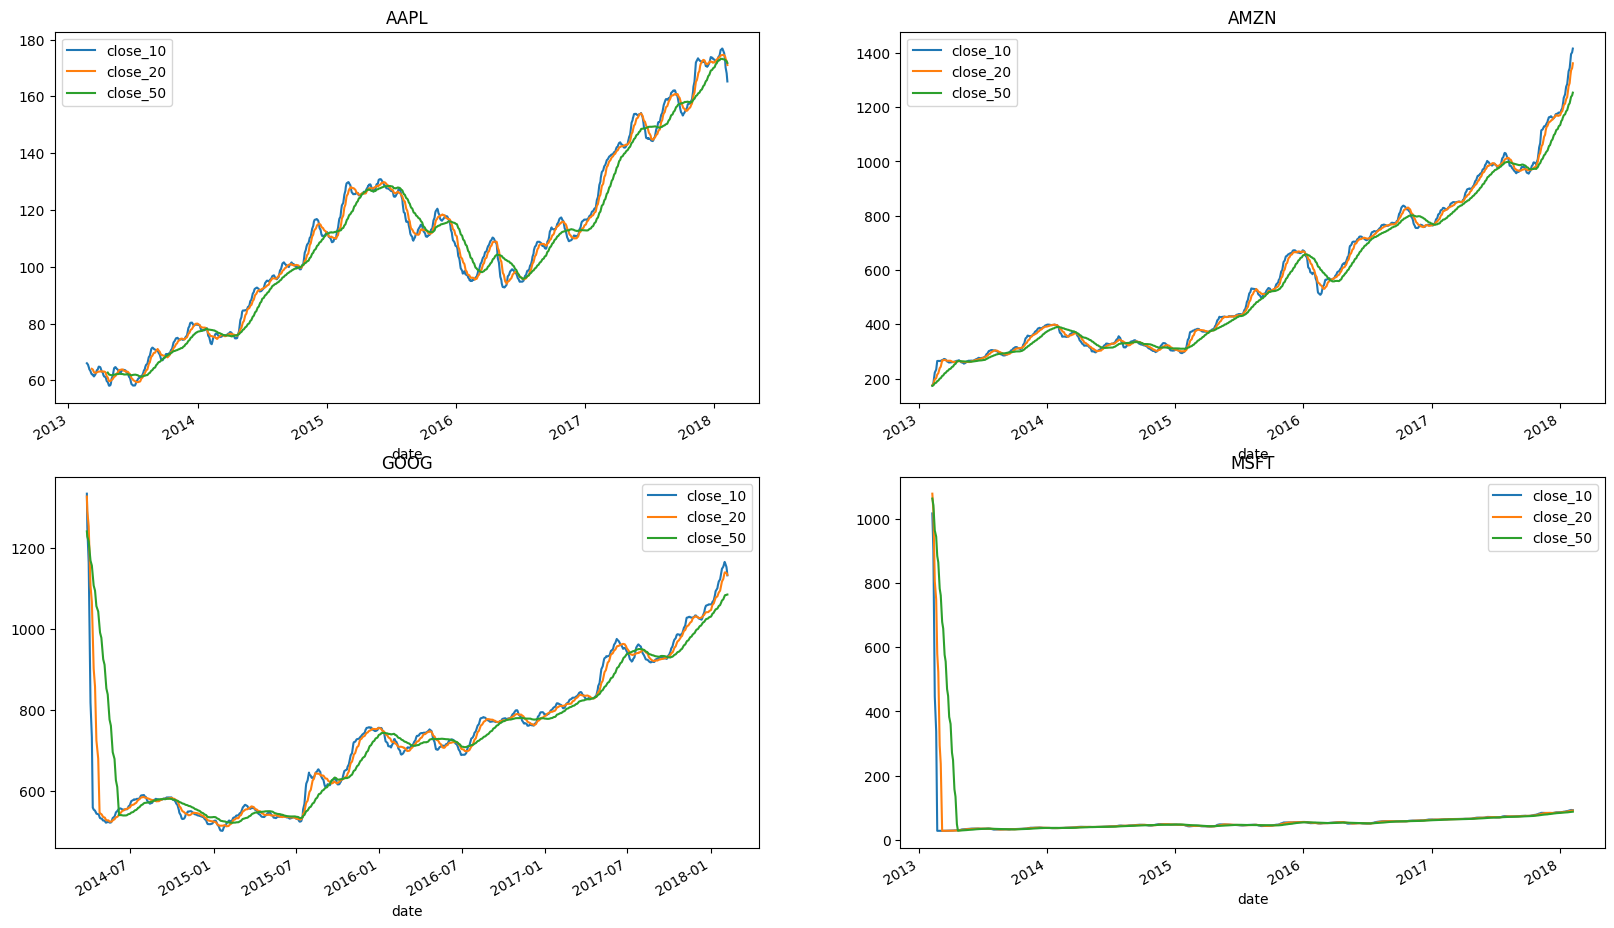

In [74]:
plt.figure(figsize=(20,12))

for index , company in enumerate(tech_list , 1):
    plt.subplot(2 , 2 , index)
    filter1 = new_data['Name']==company
    df = new_data[filter1]
    df[['close_10','close_20', 'close_50']].plot(ax=plt.gca())
    plt.title(company)

## 9. analyse Closing price change in apple stock !
##### Daily Stock Return Formula
    To calculate how much you gained or lost per day for a stock, subtract the opening price from the closing price. Then, multiply the result by the number of shares you own in the company. 

In [75]:
company_list

['D:\\\\Data_Aanalytic_Projects_DA\\\\Project - 2 Stock_price_analysis\\\\individual_stocks_5yr\\\\AAPL_data.csv',
 'D:\\\\Data_Aanalytic_Projects_DA\\\\Project - 2 Stock_price_analysis\\\\individual_stocks_5yr\\\\AMZN_data.csv',
 'D:\\\\Data_Aanalytic_Projects_DA\\\\Project - 2 Stock_price_analysis\\\\individual_stocks_5yr\\\\GOOG_data.csv',
 'D:\\\\Data_Aanalytic_Projects_DA\\\\Project - 2 Stock_price_analysis\\\\individual_stocks_5yr\\\\MSFT_data.csv']

In [76]:
apple = pd.read_csv(r'D:\\Data_Aanalytic_Projects_DA\\Project - 2 Stock_price_analysis\\individual_stocks_5yr\\AAPL_data.csv')

In [77]:
apple.head(4)

,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL


In [78]:
apple['close']

0        67.8542
1        68.5614
2        66.8428
3        66.7156
4        66.6556
          ...   
1254    167.7800
1255    160.5000
1256    156.4900
1257    163.0300
1258    159.5400
Name: close, Length: 1259, dtype: float64

In [79]:
apple.head(4)

,date,open,high,low,close,volume,Name
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL


In [80]:
apple['Daily return(in %)'] = apple['close'].pct_change() * 100

### pct_change() returns : Percentage change between the current and a prior element.

In [81]:
apple.head(4)

,date,open,high,low,close,volume,Name,Daily return(in %)
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL,NaN
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL,1.042235
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL,-2.506658
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL,-0.190297


In [82]:
import plotly.express as px

In [83]:
px.line(apple , x="date" , y="Daily return(in %)") ## Plotting Line-plot of "date" vs "Daily return(in %)"..

## 10. Performing resampling analysis of closing price ..


    Before doing resampling,first u have to make your date feature 'row-index' so that u can resample data on various basis :
    
    a..yearly('Y')  , 
    b..quarterly('Q')   ,
    c..monthly('M') ,
    d..weekly basis ('W'), 
    e..Daily_basis('D')  
    f..minutes ('3T') , 
    g..30 second bins('30S')   ,
    h..resample('17min')

In [84]:
apple.dtypes

date                   object
open                  float64
high                  float64
low                   float64
close                 float64
volume                  int64
Name                   object
Daily return(in %)    float64
dtype: object

In [85]:
apple['date'] =pd.to_datetime(apple['date'])

In [86]:
apple.dtypes

date                  datetime64[ns]
open                         float64
high                         float64
low                          float64
close                        float64
volume                         int64
Name                          object
Daily return(in %)           float64
dtype: object

In [87]:
apple.head(4)

,date,open,high,low,close,volume,Name,Daily return(in %)
0,2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL,NaN
1,2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL,1.042235
2,2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL,-2.506658
3,2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL,-0.190297


In [88]:
apple.set_index('date' , inplace=True)

In [89]:
apple.head(4)

,open,high,low,close,volume,Name,Daily return(in %)
date,,,,,,,
2013-02-08,67.7142,68.4014,66.8928,67.8542,158168416,AAPL,NaN
2013-02-11,68.0714,69.2771,67.6071,68.5614,129029425,AAPL,1.042235
2013-02-12,68.5014,68.9114,66.8205,66.8428,151829363,AAPL,-2.506658
2013-02-13,66.7442,67.6628,66.1742,66.7156,118721995,AAPL,-0.190297


In [90]:
apple['close'].resample('M').mean() ## resample data on monthly basis ..

date
2013-02-28     65.306264
2013-03-31     63.120110
2013-04-30     59.966432
2013-05-31     63.778927
2013-06-30     60.791120
                 ...    
2017-10-31    157.817273
2017-11-30    172.406190
2017-12-31    171.891500
2018-01-31    174.005238
2018-02-28    161.468000
Freq: ME, Name: close, Length: 61, dtype: float64

<Axes: xlabel='date'>

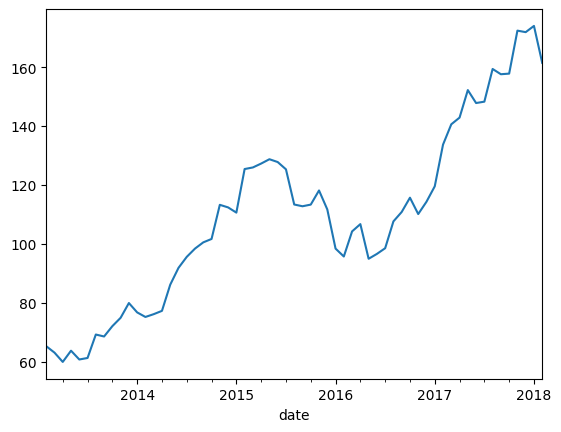

In [91]:
apple['close'].resample('M').mean().plot()

In [92]:
apple['close'].resample('Y').mean() ## resample data on Yearly basis ..

date
2013-12-31     67.237839
2014-12-31     92.264531
2015-12-31    120.039861
2016-12-31    104.604008
2017-12-31    150.585080
2018-12-31    171.594231
Freq: YE-DEC, Name: close, dtype: float64

<Axes: xlabel='date'>

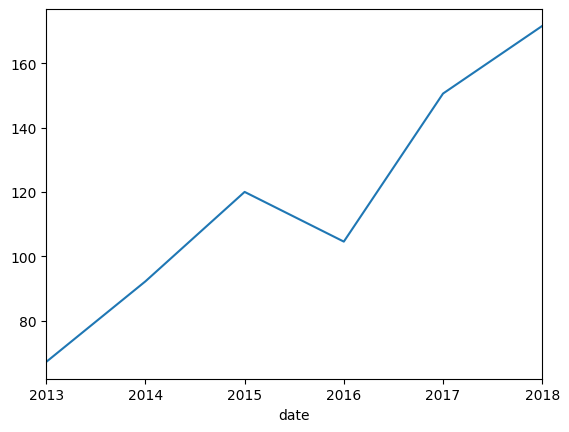

In [93]:
apple['close'].resample('Y').mean().plot() 

In [94]:
apple['close'].resample('Q').mean() ## resample data on Quarterly basis ..

date
2013-03-31     64.020291
2013-06-30     61.534692
2013-09-30     66.320670
2013-12-31     75.567478
2014-03-31     76.086293
2014-06-30     85.117475
2014-09-30     98.163311
2014-12-31    108.821016
2015-03-31    120.776721
2015-06-30    127.937937
2015-09-30    117.303438
2015-12-31    114.299297
2016-03-31     99.655082
2016-06-30     99.401250
2016-09-30    105.866094
2016-12-31    113.399048
2017-03-31    131.712500
2017-06-30    147.875397
2017-09-30    155.304603
2017-12-31    167.148254
2018-03-31    171.594231
Freq: QE-DEC, Name: close, dtype: float64

<Axes: xlabel='date'>

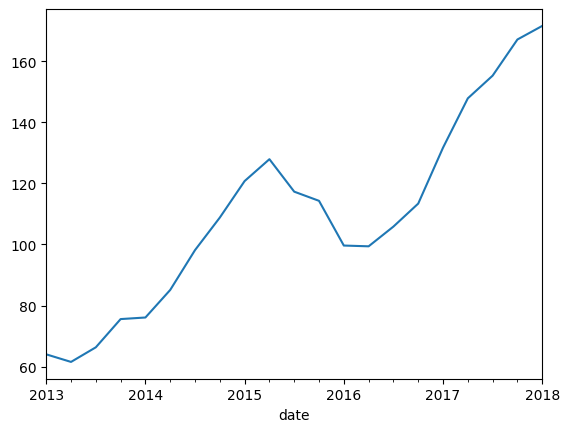

In [95]:
apple['close'].resample('Q').mean().plot()

## 11. Whether closing prices of these tech companies (Amazon,Apple,Google,Microsoft) are correlated or not !

In [96]:
company_list

['D:\\\\Data_Aanalytic_Projects_DA\\\\Project - 2 Stock_price_analysis\\\\individual_stocks_5yr\\\\AAPL_data.csv',
 'D:\\\\Data_Aanalytic_Projects_DA\\\\Project - 2 Stock_price_analysis\\\\individual_stocks_5yr\\\\AMZN_data.csv',
 'D:\\\\Data_Aanalytic_Projects_DA\\\\Project - 2 Stock_price_analysis\\\\individual_stocks_5yr\\\\GOOG_data.csv',
 'D:\\\\Data_Aanalytic_Projects_DA\\\\Project - 2 Stock_price_analysis\\\\individual_stocks_5yr\\\\MSFT_data.csv']

In [97]:
company_list[0]

'D:\\\\Data_Aanalytic_Projects_DA\\\\Project - 2 Stock_price_analysis\\\\individual_stocks_5yr\\\\AAPL_data.csv'

In [98]:
app = pd.read_csv(company_list[0])
amzn = pd.read_csv(company_list[1])
google = pd.read_csv(company_list[2])
msft = pd.read_csv(company_list[3])

In [99]:
closing_price = pd.DataFrame()

In [100]:
closing_price['apple_close'] = app['close']
closing_price['amzn_close'] = amzn['close']
closing_price['goog_close'] = google['close']
closing_price['msft_close'] = msft['close']

In [101]:
closing_price

,apple_close,amzn_close,goog_close,msft_close
0,67.8542,261.95,558.46,27.55
1,68.5614,257.21,559.99,27.86
2,66.8428,258.70,556.97,27.88
3,66.7156,269.47,567.16,28.03
4,66.6556,269.24,567.00,28.04
...,...,...,...,...
1254,167.7800,1390.00,NaN,94.26
1255,160.5000,1429.95,NaN,91.78
1256,156.4900,1390.00,NaN,88.00
1257,163.0300,1442.84,NaN,91.33


In [102]:
'''
    Pair-plot is all about , we can considering some pairs & 
    we are trying to plot scatterplot of it..
    
    Unique plots : 4c2 = 6 unique plots
    
    Total plots : 15 ( 6 unique + 6 mirror images of these 
    unique one + 3 diagonal plots(histogram))

'''


# Dis-advantages: 
## Can't be used when number of features are high.
## Cannot visualize higher dimensional patterns in 3-D and 4-D. 
## Only possible to view 2D patterns.



# NOTE: the diagnol elements are (histogram) for each feature.

'\n    Pair-plot is all about , we can considering some pairs & \n    we are trying to plot scatterplot of it..\n\n    Unique plots : 4c2 = 6 unique plots\n\n    Total plots : 15 ( 6 unique + 6 mirror images of these \n    unique one + 3 diagonal plots(histogram))\n\n'

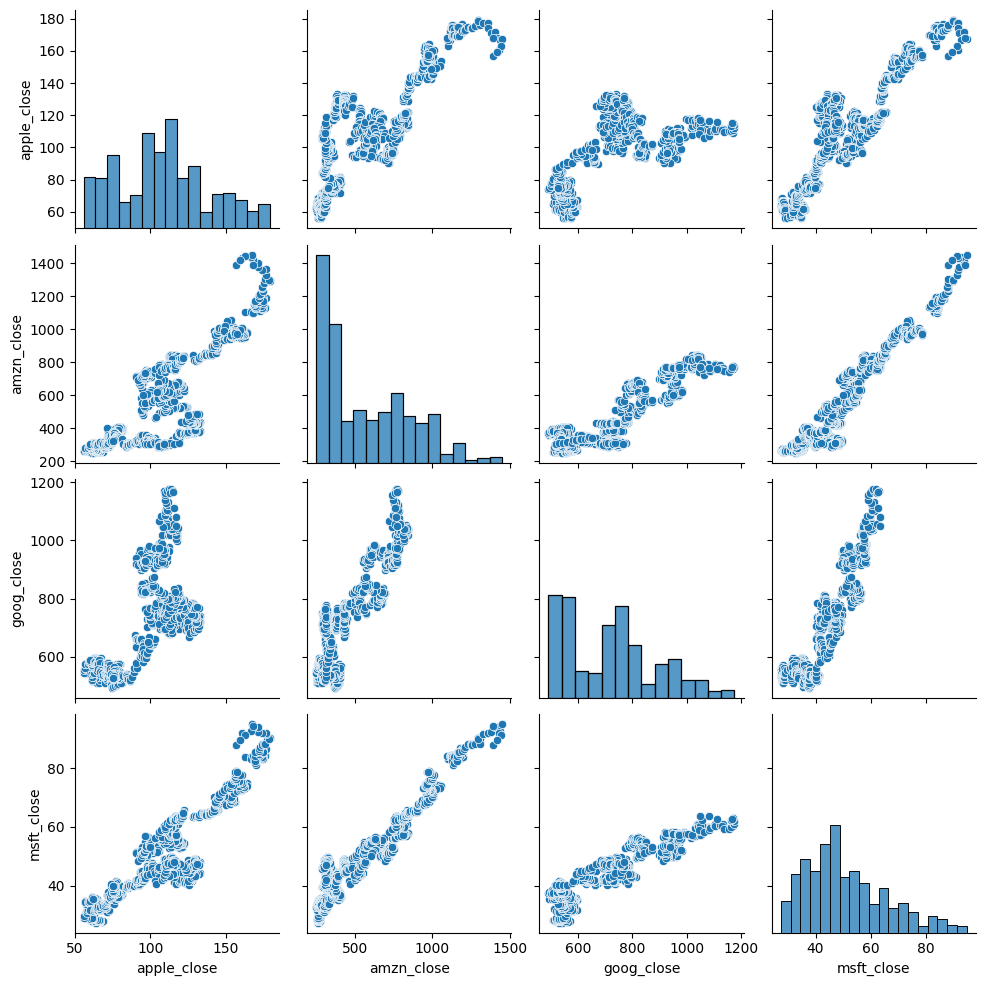

In [103]:
sns.pairplot(closing_price)

In [104]:
closing_price.corr()

,apple_close,amzn_close,goog_close,msft_close
apple_close,1.000000,0.819078,0.640522,0.899689
amzn_close,0.819078,1.000000,0.888456,0.955977
goog_close,0.640522,0.888456,1.000000,0.907011
msft_close,0.899689,0.955977,0.907011,1.000000


#### co-relation plot for stock prices

<Axes: >

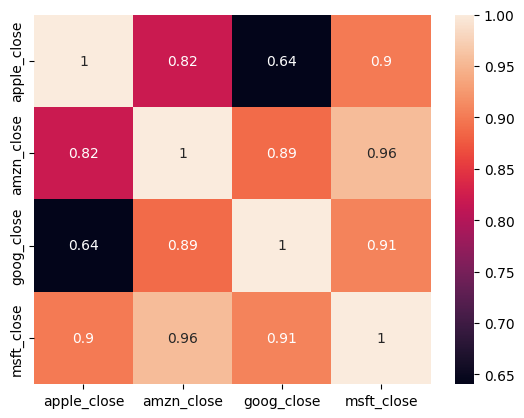

In [105]:
sns.heatmap(closing_price.corr() , annot=True)

In [106]:
'''

Conclusions : 
Closing price of Google and Microsoft are well correlated
& Closing price of Amazon and Microsoft have a co-relation of 0.96


'''

'\n\nConclusions : \nClosing price of Google and Microsoft are well correlated\n& Closing price of Amazon and Microsoft have a co-relation of 0.96\n\n\n'

## 12. analyse Whether Daily change in Closing price of stocks or Daily Returns in Stock are co-related or not !

In [107]:
closing_price

,apple_close,amzn_close,goog_close,msft_close
0,67.8542,261.95,558.46,27.55
1,68.5614,257.21,559.99,27.86
2,66.8428,258.70,556.97,27.88
3,66.7156,269.47,567.16,28.03
4,66.6556,269.24,567.00,28.04
...,...,...,...,...
1254,167.7800,1390.00,NaN,94.26
1255,160.5000,1429.95,NaN,91.78
1256,156.4900,1390.00,NaN,88.00
1257,163.0300,1442.84,NaN,91.33


In [108]:
closing_price['apple_close']

0        67.8542
1        68.5614
2        66.8428
3        66.7156
4        66.6556
          ...   
1254    167.7800
1255    160.5000
1256    156.4900
1257    163.0300
1258    159.5400
Name: apple_close, Length: 1259, dtype: float64

In [109]:
closing_price['apple_close'].shift(1)

0            NaN
1        67.8542
2        68.5614
3        66.8428
4        66.7156
          ...   
1254    167.4300
1255    167.7800
1256    160.5000
1257    156.4900
1258    163.0300
Name: apple_close, Length: 1259, dtype: float64

In [110]:
(closing_price['apple_close'] - closing_price['apple_close'].shift(1))/closing_price['apple_close'].shift(1) * 100

0            NaN
1       1.042235
2      -2.506658
3      -0.190297
4      -0.089934
          ...   
1254    0.209043
1255   -4.339015
1256   -2.498442
1257    4.179181
1258   -2.140710
Name: apple_close, Length: 1259, dtype: float64

In [111]:
for col in closing_price.columns:
    closing_price[col + '_pct_change'] = (closing_price[col] - closing_price[col].shift(1))/closing_price[col].shift(1) * 100

In [112]:
closing_price

,apple_close,amzn_close,goog_close,msft_close,apple_close_pct_change,amzn_close_pct_change,goog_close_pct_change,msft_close_pct_change
0,67.8542,261.95,558.46,27.55,NaN,NaN,NaN,NaN
1,68.5614,257.21,559.99,27.86,1.042235,-1.809506,0.273968,1.125227
2,66.8428,258.70,556.97,27.88,-2.506658,0.579293,-0.539295,0.071788
3,66.7156,269.47,567.16,28.03,-0.190297,4.163123,1.829542,0.538020
4,66.6556,269.24,567.00,28.04,-0.089934,-0.085353,-0.028211,0.035676
...,...,...,...,...,...,...,...,...
1254,167.7800,1390.00,NaN,94.26,0.209043,-4.196734,NaN,-0.789391
1255,160.5000,1429.95,NaN,91.78,-4.339015,2.874101,NaN,-2.631021
1256,156.4900,1390.00,NaN,88.00,-2.498442,-2.793804,NaN,-4.118544
1257,163.0300,1442.84,NaN,91.33,4.179181,3.801439,NaN,3.784091


In [113]:
closing_price.columns

Index(['apple_close', 'amzn_close', 'goog_close', 'msft_close',
       'apple_close_pct_change', 'amzn_close_pct_change',
       'goog_close_pct_change', 'msft_close_pct_change'],
      dtype='object')

In [114]:
clsing_p = closing_price[['apple_close_pct_change', 'amzn_close_pct_change',
       'goog_close_pct_change', 'msft_close_pct_change']]

In [115]:
clsing_p

,apple_close_pct_change,amzn_close_pct_change,goog_close_pct_change,msft_close_pct_change
0,NaN,NaN,NaN,NaN
1,1.042235,-1.809506,0.273968,1.125227
2,-2.506658,0.579293,-0.539295,0.071788
3,-0.190297,4.163123,1.829542,0.538020
4,-0.089934,-0.085353,-0.028211,0.035676
...,...,...,...,...
1254,0.209043,-4.196734,NaN,-0.789391
1255,-4.339015,2.874101,NaN,-2.631021
1256,-2.498442,-2.793804,NaN,-4.118544
1257,4.179181,3.801439,NaN,3.784091


In [116]:
### since we have used Pairplot already , lets use extension of Pairplot , ie Pairgrid :

In [117]:
'''
Pairplot : we have histogram on diagonals & scatterplot/kde/
            any_other_plot which tells dist.. on rest of the plot 


Pairgrid : Once we create grid , we can set plot as per our need : 

ie , if we have 4 features , it creates total 16 graphs/plots or matrices of 4*4



    There would be various possibilities for type of plots in our Pairgrid which we can set as per our need :

    a) all plots can be scatterplot
    b) on diagonal , we have histogram & rest will be scatterplot
    c) on diagonal , we have histogram & rest will be kdeplot 
    c) on diagonal , we have histogram & below diagonal will be kdeplot
            & upper diagonal will be scatterplot 

Note :: kdeplot for 2 features also known as contour plots which returns density
but kdeplot returns distribution if we are performing univariate analysis else it will show density ..

'''

'\nPairplot : we have histogram on diagonals & scatterplot/kde/\n            any_other_plot which tells dist.. on rest of the plot \n\n\nPairgrid : Once we create grid , we can set plot as per our need : \n\nie , if we have 4 features , it creates total 16 graphs/plots or matrices of 4*4\n\n\n\n    There would be various possibilities for type of plots in our Pairgrid which we can set as per our need :\n\n    a) all plots can be scatterplot\n    b) on diagonal , we have histogram & rest will be scatterplot\n    c) on diagonal , we have histogram & rest will be kdeplot \n    c) on diagonal , we have histogram & below diagonal will be kdeplot\n            & upper diagonal will be scatterplot \n\nNote :: kdeplot for 2 features also known as contour plots which returns density\nbut kdeplot returns distribution if we are performing univariate analysis else it will show density ..\n\n'

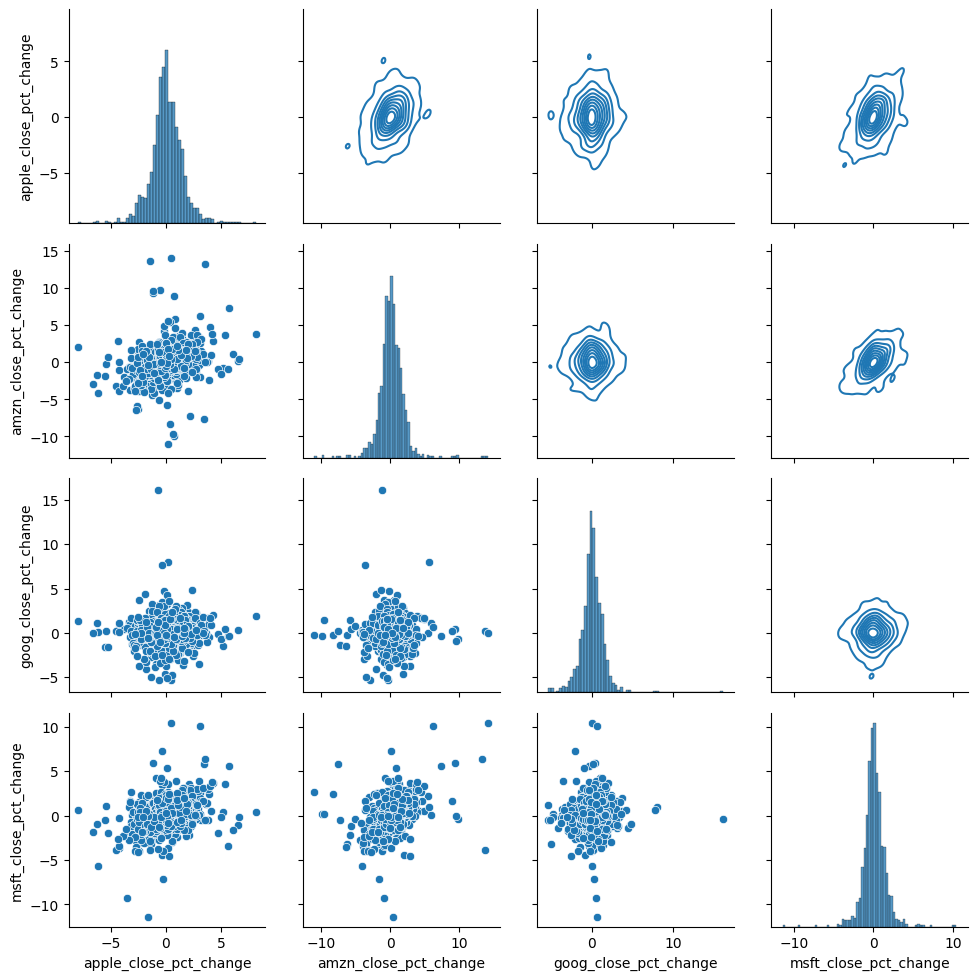

In [118]:
g = sns.PairGrid(data= clsing_p)
g.map_diag(sns.histplot)
g.map_lower(sns.scatterplot)
g.map_upper(sns.kdeplot)

In [119]:
'''

Conclusion :
While Comparing 'AAPL_close_pct_change' to 'AMZN_close_pct_change'  , it shows a linear relationship upto some extent..


'''

"\n\nConclusion :\nWhile Comparing 'AAPL_close_pct_change' to 'AMZN_close_pct_change'  , it shows a linear relationship upto some extent..\n\n\n"

In [120]:
clsing_p.corr()

,apple_close_pct_change,amzn_close_pct_change,goog_close_pct_change,msft_close_pct_change
apple_close_pct_change,1.000000,0.287659,0.036202,0.366598
amzn_close_pct_change,0.287659,1.000000,0.027698,0.402678
goog_close_pct_change,0.036202,0.027698,1.000000,0.038939
msft_close_pct_change,0.366598,0.402678,0.038939,1.000000


# 13. best month to invest in each stock 

In [121]:
all_data["month_name"] = all_data["date"].dt.month_name()

monthly_returns = all_data.groupby(["Name", "month_name"])["daily_return"].mean().reset_index()

monthly_returns

,Name,month_name,daily_return
0,AAPL,April,-0.000335
1,AAPL,August,0.001834
2,AAPL,December,-0.001343
3,AAPL,February,0.001532
4,AAPL,January,-0.000770
5,AAPL,July,0.002413
6,AAPL,June,-0.002175
7,AAPL,March,0.001537
8,AAPL,May,0.002444
9,AAPL,November,0.001438


In [123]:
monthly_returns.columns

px.bar(monthly_returns,
    x = "month_name",
    y = "daily_return",
    color = "Name",
    barmode = "group",
    title = "Average Monthly Returns by stock")